In [99]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [100]:
df = pd.read_csv('datasets/ds1_train.csv')

train = df.sample(frac=0.8, random_state=4242)
test = df.drop(train.index)

y_train = train['y'].to_numpy()
X_train = train.drop(columns='y').to_numpy()
y_test = test['y'].to_numpy()
X_test = test.drop(columns='y').to_numpy()

In [ ]:
lr = 0.1
epoches = 1000
X_train = np.hstack((np.ones((X_train.shape[0], 1)), X_train))
beta = np.zeros(X_train.shape[1])
losses = []
v = 0


def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def loss_fun(y, y_hat):
    eps = 1e-15
    y_hat = np.clip(y_hat, eps, 1-eps)
    return np.mean(-y * np.log(y_hat) - (1-y) * np.log(1-y_hat))

for _ in range(epoches):
    y_hat = sigmoid(X_train @ beta)
    loss = loss_fun(y_train, y_hat)
    losses.append(loss)
    gradient = X_train.T @ (y_hat - y_train) / len(y_train)

    # beta -= lr * gradient

    # beta -= lr * (gradient + 0.1 * beta)  # L2 regularization

    # v = v * 0.9 + lr * gradient  # Momentum
    # beta -= v

    # H = X_train.T @ X_train / len(y_train)
    # beta -= lr * np.linalg.inv(H) @ gradient  # Newton's method

accuracy = np.mean((sigmoid(np.hstack((np.ones((X_test.shape[0], 1)), X_test)) @ beta) >= 0.5) == y_test) * 100

print(f"Accuracy: {accuracy:.2f}%")


Accuracy: 76.88%


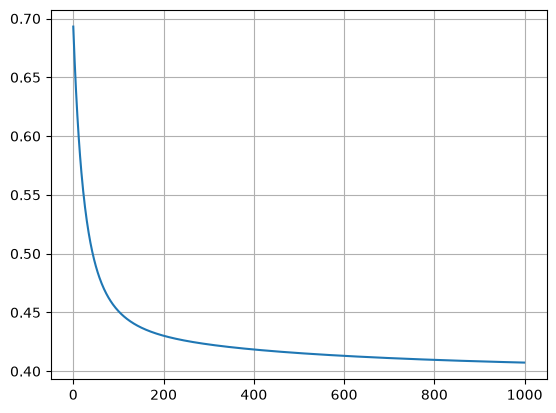

In [102]:
plt.plot(losses)
plt.grid(True)
plt.show()